[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_ewma_weights/BA_L4_ewma_weights.ipynb)

# BA_L4_ewma_weights: How EWMA weights the past

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Weights of the exponentially weighted moving average (EWMA, RiskMetrics) on past squared returns for decay factors 0.94 and 0.97, compared with a 30-day window of equal weights; computed from the formula, no data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Method.** The EWMA (RiskMetrics) variance recursion
$$ \sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1 - \lambda)\,\varepsilon_{t-1}^2 = (1 - \lambda)\sum_{j \ge 1}\lambda^{j-1}\varepsilon_{t-j}^2 $$
puts the weight $(1-\lambda)\lambda^{j-1}$ on the squared return of $j$ days ago. The weights decay geometrically; the effective memory is $1/(1-\lambda)$ days.

**How to read.** Bars: EWMA weights for $\lambda = 0.94$ and $0.97$; dashed red line: equal weights $1/30$ in a 30-day window, which drop to zero on day 31.

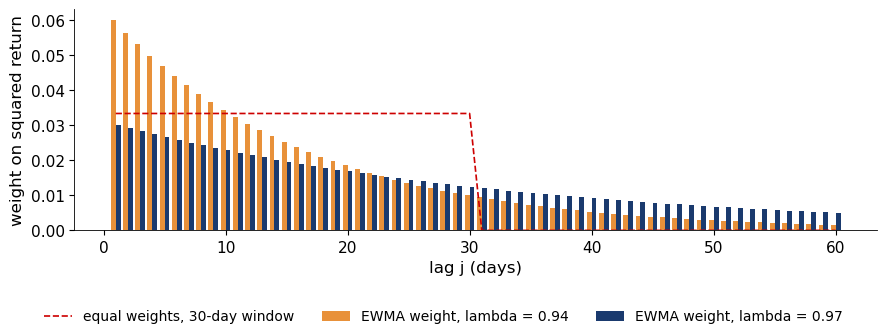

In [4]:
j = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(9, 3.4))
for lam_, col, dx in [(0.94, BTC, -0.2), (0.97, BLUE, 0.2)]:
    ax.bar(j + dx, (1 - lam_) * lam_ ** (j - 1), width=0.4, color=col, label=f'EWMA weight, lambda = {lam_}')
ax.plot(j, np.where(j <= 30, 1 / 30, 0), color=RED, ls='--', lw=1.2, label='equal weights, 30-day window')
ax.set_xlabel('lag j (days)'); ax.set_ylabel('weight on squared return')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1))
save_fig(fig, 'ba_l4_ewma_weights')

**Key numbers** (as on the slide).

In [5]:
lam = 0.94
pd.Series({'weight on yesterday (%)': 100 * (1 - lam), 'weight on day 30 (%)': 100 * (1 - lam) * lam ** 29,
           'share of the weight carried by the last 30 days (%)': 100 * (1 - lam ** 30),
           'effective memory 1/(1 - lambda) (days)': 1 / (1 - lam)}).round(2).to_frame('lambda = 0.94')

,lambda = 0.94
weight on yesterday (%),6.00
weight on day 30 (%),1.00
share of the weight carried by the last 30 days (%),84.37
effective memory 1/(1 - lambda) (days),16.67
